In [3]:
import pandas as pd
import re

# ============================================================
# BUILD LONG TABLE (VALUES IN PERCENT, NO ROUNDING)
# ============================================================

files = {
    "Retired persons.xlsx": "Retired",
    "Unemployed persons.xlsx": "Unemployed",
    "Employed persons except employees.xlsx": "Self-employed",
    "Non-manual workers in industry and services.xlsx": "Non-manual",
    "Manual workers in industry and services.xlsx": "Manual",
}

all_long = []
for filename, status in files.items():
    df = pd.read_excel(filename, header=None)
    year_row = df.iloc[9].tolist()
    data = df.iloc[11:].copy().rename(columns={0: "Country"})
    for idx, val in enumerate(year_row):
        if pd.notna(val) and str(val).strip().isdigit():
            temp = data[["Country", idx]].copy()
            temp.columns = ["Country", "raw_value"]
            temp["Year"] = int(val)
            temp["Employment Status"] = status
            all_long.append(temp)

df = pd.concat(all_long, ignore_index=True)
df = df[df["Country"].notna()]
df = df[~df["Country"].astype(str).str.strip().isin(["", "Special value", "Observation flags:"])]
df = df[~df["Country"].astype(str).str.startswith((":", "e", "i", "u"))]

def parse_value(v):
    if pd.isna(v):
        return (None, None)
    s = str(v).strip()
    if s in [":", "", "nan"]:
        return (None, None)
    m = re.match(r"^([\d.,]+)\s*([eiu]?)$", s)
    if m:
        try:
            return (float(m.group(1).replace(",", ".")), m.group(2) or None)
        except ValueError:
            return (None, None)
    return (None, None)

parsed = df["raw_value"].apply(parse_value)
df["Value per mille"] = [p[0] for p in parsed]
df["Flag"] = [p[1] for p in parsed]

# Convert per mille to percent (divide by 10, NO rounding)
df["Food Expenditure Share (%)"] = df["Value per mille"] / 10

df_countries = df[~df["Country"].astype(str).str.startswith("European Union")].copy()
df_countries = df_countries[["Country", "Year", "Employment Status", "Food Expenditure Share (%)", "Flag"]]
df_countries = df_countries.sort_values(["Country", "Year", "Employment Status"]).reset_index(drop=True)

df_countries.to_csv("long_table.csv", index=False)

print(f"Total rows: {len(df_countries)}")
print(f"With value: {df_countries['Food Expenditure Share (%)'].notna().sum()}")
print(f"Missing: {df_countries['Food Expenditure Share (%)'].isna().sum()}")
print()
print("First 15 rows:")
print(df_countries.head(15).to_string(index=False))
print()
print("Saved: long_table.csv")

Total rows: 1190
With value: 734
Missing: 456

First 15 rows:
Country  Year Employment Status  Food Expenditure Share (%) Flag
Austria  1988            Manual                         NaN None
Austria  1988        Non-manual                         NaN None
Austria  1988           Retired                         NaN None
Austria  1988     Self-employed                         NaN None
Austria  1988        Unemployed                         NaN None
Austria  1994            Manual                       15.17 None
Austria  1994        Non-manual                       11.87 None
Austria  1994           Retired                       15.16 None
Austria  1994     Self-employed                       15.90 None
Austria  1994        Unemployed                       14.38 None
Austria  1999            Manual                       13.19 None
Austria  1999        Non-manual                        9.61 None
Austria  1999           Retired                       13.90 None
Austria  1999     Self-emplo

Final average food expenditure share by employment status (%):
Employment Status
Non-manual       13.8458
Self-employed    16.9278
Manual           17.1971
Retired          18.7869
Unemployed       18.8259



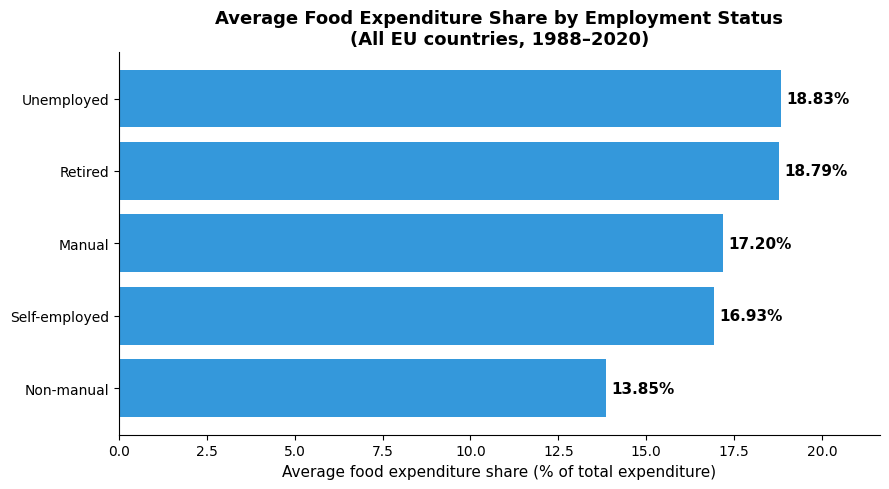

Saved: ranking_status.png


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# RANKING: AVERAGE FOOD EXPENDITURE SHARE BY EMPLOYMENT STATUS
# ============================================================
# Step 1: average per (status, year) — NaN skipped, not treated as 0
# Step 2: average of yearly averages per status
# Output: horizontal bar chart, sorted descending

df = pd.read_csv("long_table.csv")

# Step 1: yearly average per status
yearly = (
    df.dropna(subset=["Food Expenditure Share (%)"])
      .groupby(["Employment Status", "Year"])["Food Expenditure Share (%)"]
      .mean()
      .reset_index()
)

# Step 2: cumulative average per status
final = (
    yearly.groupby("Employment Status")["Food Expenditure Share (%)"]
          .mean()
          .sort_values(ascending=True)   # ascending for horizontal bar (largest on top)
)

print("Final average food expenditure share by employment status (%):")
print(final.round(4).to_string())
print()

# Chart
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(final.index, final.values, color="#3498db")

for bar, val in zip(bars, final.values):
    ax.text(val + 0.15, bar.get_y() + bar.get_height()/2,
            f"{val:.2f}%", va="center", fontsize=11, fontweight="bold")

ax.set_xlabel("Average food expenditure share (% of total expenditure)", fontsize=11)
ax.set_title("Average Food Expenditure Share by Employment Status\n(All EU countries, 1988–2020)", fontsize=13, fontweight="bold")
ax.set_xlim(0, final.max() * 1.15)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("ranking_status.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: ranking_status.png")

Yearly average food expenditure share by employment status (%):
Employment Status  Manual  Non-manual  Retired  Self-employed  Unemployed
Year                                                                     
1988                20.02       15.92    21.51          19.59       21.59
1994                15.76       12.74    16.75          15.40       16.61
1999                14.19       11.02    15.32          13.44       15.48
2005                17.73       13.95    20.52          18.27       20.72
2010                17.25       13.78    19.58          17.78       18.38
2015                17.86       14.82    19.20          17.53       19.84
2020                17.57       14.69    18.64          16.48       19.17



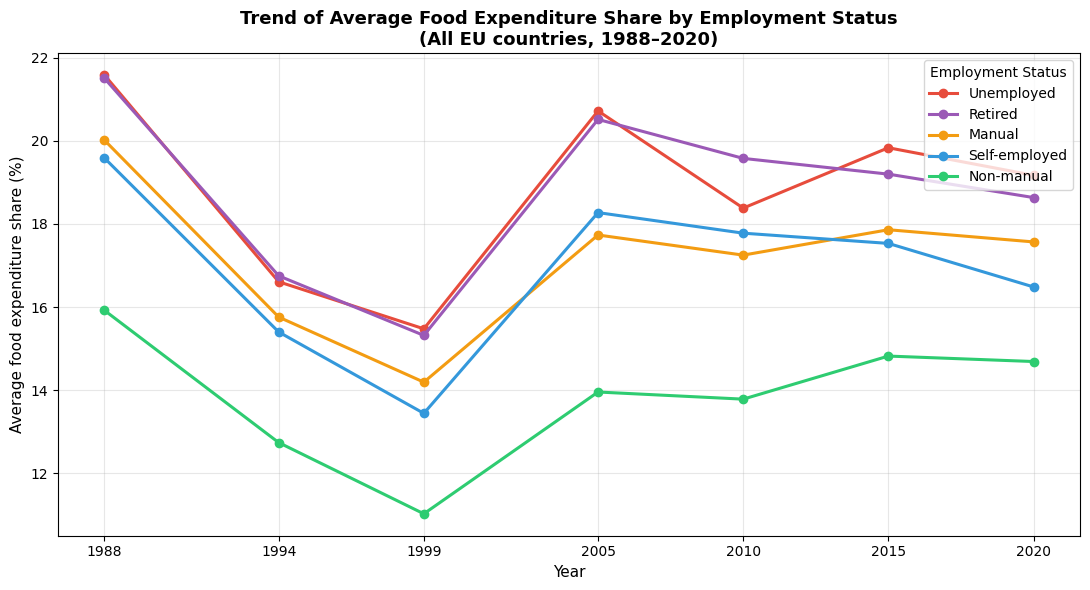

Saved: trend_status.png


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# TREND: AVERAGE FOOD EXPENDITURE SHARE BY STATUS OVER TIME
# ============================================================
# Uses Step 1 output: average per (status, year)
# NaN skipped, not treated as 0

df = pd.read_csv("long_table.csv")

# Step 1: yearly average per status
yearly = (
    df.dropna(subset=["Food Expenditure Share (%)"])
      .groupby(["Employment Status", "Year"])["Food Expenditure Share (%)"]
      .mean()
      .reset_index()
)

# Pivot: rows = Year, columns = Employment Status
trend = yearly.pivot(index="Year", columns="Employment Status", values="Food Expenditure Share (%)")
trend = trend.sort_index()

print("Yearly average food expenditure share by employment status (%):")
print(trend.round(2).to_string())
print()

# Chart
colors = {
    "Unemployed": "#e74c3c",
    "Retired": "#9b59b6",
    "Manual": "#f39c12",
    "Self-employed": "#3498db",
    "Non-manual": "#2ecc71",
}

fig, ax = plt.subplots(figsize=(11, 6))

for status in ["Unemployed", "Retired", "Manual", "Self-employed", "Non-manual"]:
    if status in trend.columns:
        ax.plot(trend.index, trend[status], marker="o", linewidth=2.2,
                label=status, color=colors[status], markersize=6)

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Average food expenditure share (%)", fontsize=11)
ax.set_title("Trend of Average Food Expenditure Share by Employment Status\n(All EU countries, 1988–2020)", fontsize=13, fontweight="bold")
ax.legend(title="Employment Status", loc="upper right", fontsize=10)
ax.grid(alpha=0.3)
ax.set_xticks(trend.index)

plt.tight_layout()
plt.savefig("trend_status.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: trend_status.png")

Latest year in data: 2020
Countries with complete data in 2020: 25


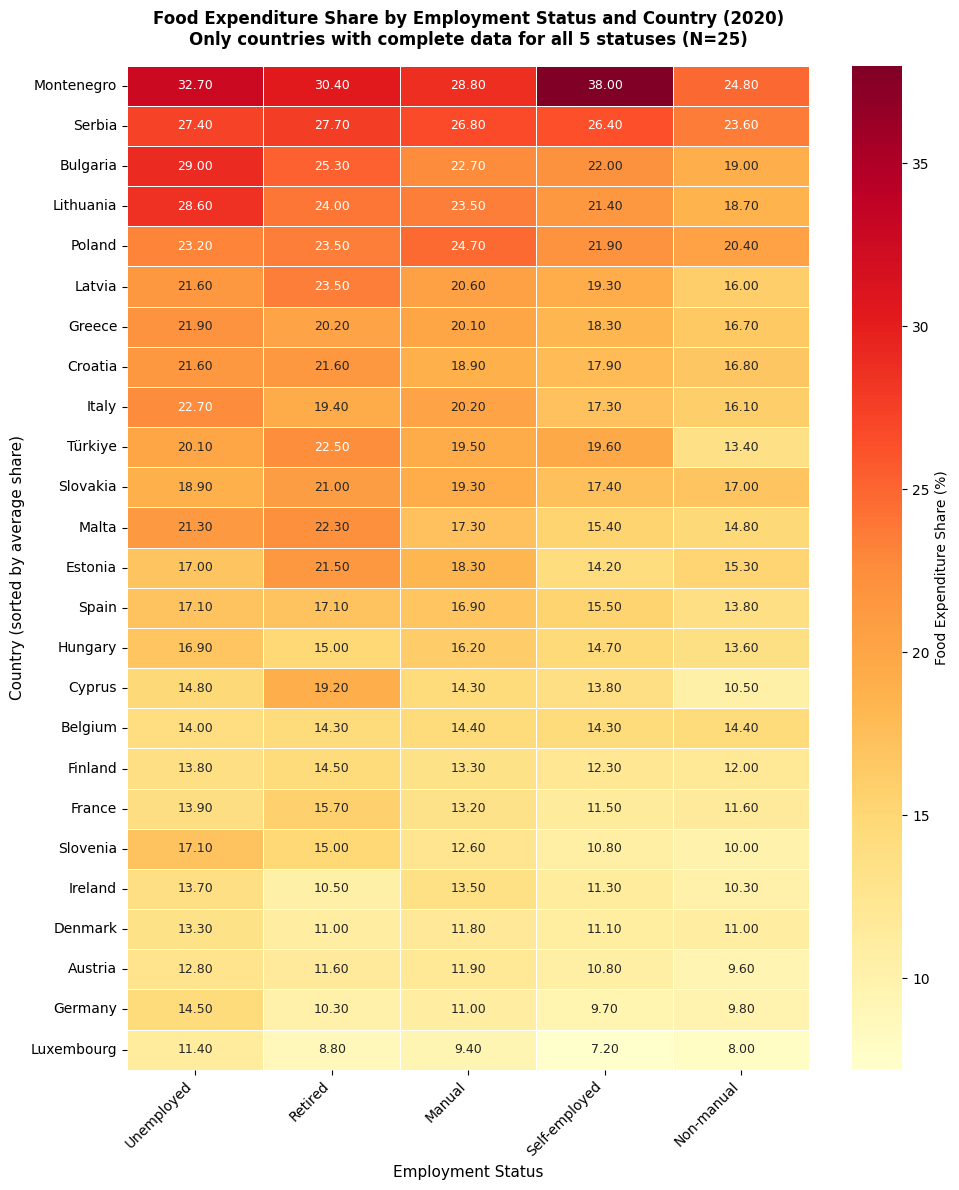


Saved: heatmap_2020.png


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# HEATMAP: HIGHEST FOOD EXPENDITURE SHARE PER COUNTRY (LATEST YEAR)
# ============================================================
# Rules:
# 1. Use the most recent year available in the dataset
# 2. Only include countries with ALL 5 statuses filled (no NaN)
# 3. Show values in percent

df = pd.read_csv("long_table.csv")

# 1. Find the most recent year
latest_year = df["Year"].max()
print(f"Latest year in data: {latest_year}")

# 2. Filter for the latest year only
df_latest = df[df["Year"] == latest_year].copy()

# 3. Drop rows where value is NaN (missing)
df_latest = df_latest.dropna(subset=["Food Expenditure Share (%)"])

# 4. Find countries that have exactly 5 statuses
status_counts = df_latest.groupby("Country")["Employment Status"].nunique()
complete_countries = status_counts[status_counts == 5].index.tolist()

print(f"Countries with complete data in {latest_year}: {len(complete_countries)}")

# 5. Filter the data to only complete countries
df_complete = df_latest[df_latest["Country"].isin(complete_countries)]

# 6. Pivot to create the heatmap matrix (Rows = Country, Columns = Status)
pivot = df_complete.pivot(index="Country", columns="Employment Status", values="Food Expenditure Share (%)")

# Sort columns based on the European average ranking (highest to lowest)
column_order = ["Unemployed", "Retired", "Manual", "Self-employed", "Non-manual"]
column_order = [c for c in column_order if c in pivot.columns]
pivot = pivot[column_order]

# Sort countries by average share (highest at the top)
pivot["Average"] = pivot.mean(axis=1)
pivot = pivot.sort_values("Average", ascending=False).drop(columns="Average")

# ============================================================
# PLOT HEATMAP
# ============================================================

plt.figure(figsize=(10, 12))

# Color map: YlOrRd (Yellow -> Orange -> Red)
# Darker red indicates higher % of food expenditure (more constrained)
ax = sns.heatmap(pivot,
                 annot=True,       # Display values
                 fmt=".2f",        # 2 decimal places
                 cmap="YlOrRd",    # Color palette
                 linewidths=.5,    # Grid lines
                 cbar_kws={'label': 'Food Expenditure Share (%)'},
                 annot_kws={"size": 9})

plt.title(f"Food Expenditure Share by Employment Status and Country ({latest_year})\nOnly countries with complete data for all 5 statuses (N={len(complete_countries)})",
          fontsize=12, fontweight="bold", pad=15)
plt.xlabel("Employment Status", fontsize=11)
plt.ylabel("Country (sorted by average share)", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig("heatmap_2020.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nSaved: heatmap_2020.png")

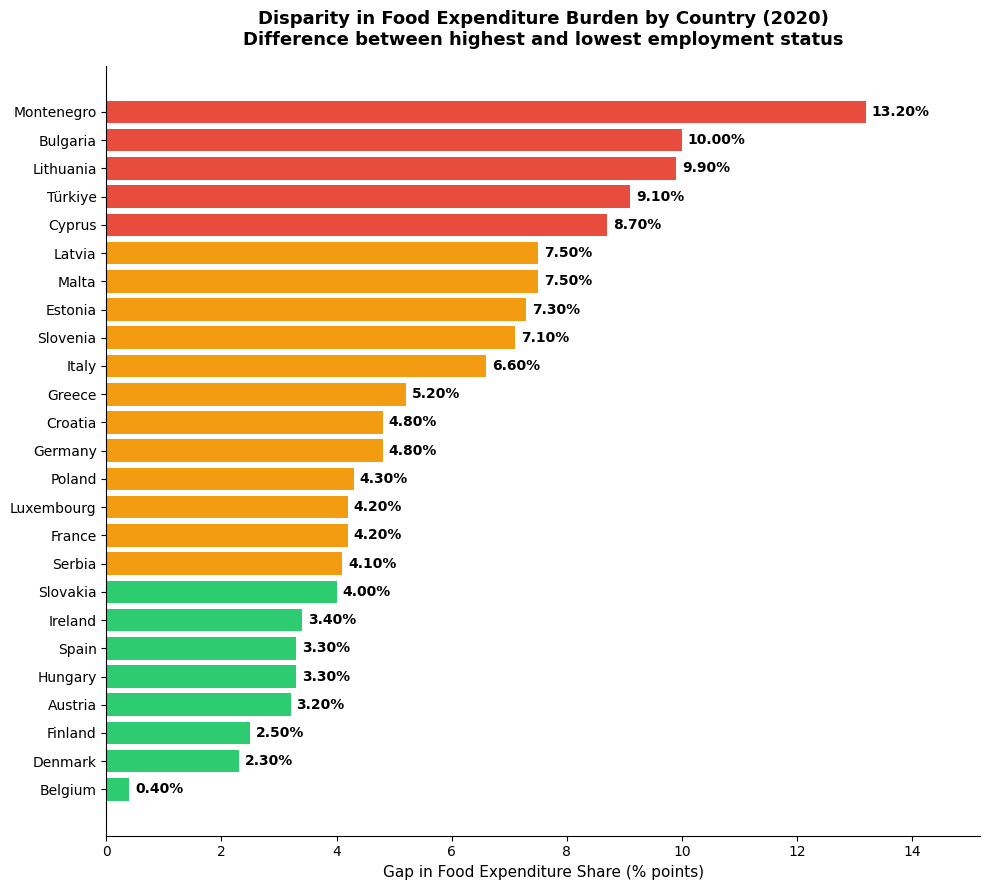

Top 5 countries with largest gap (highest disparity):
   Country  Gap
    Cyprus  8.7
   Türkiye  9.1
 Lithuania  9.9
  Bulgaria 10.0
Montenegro 13.2

Top 5 countries with smallest gap (most equal):
Country  Gap
Belgium  0.4
Denmark  2.3
Finland  2.5
Austria  3.2
Hungary  3.3

Saved: gap_2020.png


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# GAP IN FOOD EXPENDITURE SHARE BY COUNTRY (2020)
# ============================================================
# Gap = (Highest Status Share) - (Lowest Status Share)
# Rules: Same as heatmap (2020, complete countries only)

df = pd.read_csv("long_table.csv")

# 1. Filter for 2020
df_2020 = df[df["Year"] == 2020].copy()

# 2. Drop missing values
df_2020 = df_2020.dropna(subset=["Food Expenditure Share (%)"])

# 3. Filter for countries with complete 5 statuses
status_counts = df_2020.groupby("Country")["Employment Status"].nunique()
complete_countries = status_counts[status_counts == 5].index.tolist()
df_complete = df_2020[df_2020["Country"].isin(complete_countries)]

# 4. Calculate Gap (Max - Min) per country
def calculate_gap(group):
    return group.max() - group.min()

gap_data = df_complete.groupby("Country")["Food Expenditure Share (%)"].agg(
    Highest="max",
    Lowest="min",
    Gap=lambda x: x.max() - x.min()
).reset_index()

# Sort from largest to smallest gap
gap_data = gap_data.sort_values("Gap", ascending=True)

# ============================================================
# PLOT BAR CHART
# ============================================================

fig, ax = plt.subplots(figsize=(10, 9))

# Bar colors: red for large gap, green for small gap
colors = ["#e74c3c" if v > 8 else "#f39c12" if v > 4 else "#2ecc71" for v in gap_data["Gap"]]

bars = ax.barh(gap_data["Country"], gap_data["Gap"], color=colors)

# Add value labels at the end of each bar
for bar, val in zip(bars, gap_data["Gap"]):
    ax.text(val + 0.1, bar.get_y() + bar.get_height()/2,
            f"{val:.2f}%", va="center", fontsize=10, fontweight="bold")

ax.set_xlabel("Gap in Food Expenditure Share (% points)", fontsize=11)
ax.set_title("Disparity in Food Expenditure Burden by Country (2020)\nDifference between highest and lowest employment status",
             fontsize=13, fontweight="bold", pad=15)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, gap_data["Gap"].max() * 1.15)

plt.tight_layout()
plt.savefig("gap_2020.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 5 countries with largest gap (highest disparity):")
print(gap_data.tail(5)[["Country", "Gap"]].to_string(index=False))
print("\nTop 5 countries with smallest gap (most equal):")
print(gap_data.head(5)[["Country", "Gap"]].to_string(index=False))
print("\nSaved: gap_2020.png")